# Computer Vision Project — Image Matching

## Overview

Matching images of the same object seen from different viewpoints, using only **edges** as detection primitives, then comparing this with running SIFT on the full image.

Dataset: [dino-images](<!-- add your dataset link here -->), 3 views of a stegosaurus from the [Middlebury multi-view datasets](https://vision.middlebury.edu/mview/data/).

## Pipeline

Images → LoG (edges) → Morphological dilation → SIFT on mask → FLANN matching
↕ comparison with SIFT on the full image → FLANN matching

1. **Edge extraction**: Laplacian of Gaussian (LoG) filter and thresholding, then morphological dilation (5×5 elliptical kernel)
2. **SIFT detection** restricted to the dilated edge mask, with keypoint counts per image
3. **FLANN matching** (KD-tree) with Lowe's ratio test (0.75) on the 3 image pairs
4. **Comparison**: the same procedure with SIFT on the full image, without a mask

## Findings

On these views of a single object on a dark background, restricting SIFT to the edge mask gave almost the same result as using the full image: **88 valid matches in total in both cases**. The notebook discusses why, and when a mask would matter more (cluttered backgrounds).

Course project, Univesity of Science and technology Mohamed Boudiaf of ORAN (Master AI & Applications, 2025/2026).

---
## Imports and configuration

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_laplace

# Check the OpenCV version (SIFT is included in OpenCV >= 4.4; older versions need the contrib build)
print(f"OpenCV version: {cv2.__version__}")
print(f"SIFT available: {hasattr(cv2, 'SIFT_create')}")

# Matplotlib style
plt.rcParams['figure.figsize'] = (15, 5)
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.titleweight'] = 'bold'

OpenCV version: 4.14.0
SIFT available: True


---
# PART 1 — Edge extraction

## 1.1 Loading the images

The 3 images show the **same object** (a stegosaurus) photographed from **3 different angles**.

We load each image in **grayscale** because:
- LoG and SIFT operate on single-channel images
- Colour adds no extra information for edge detection

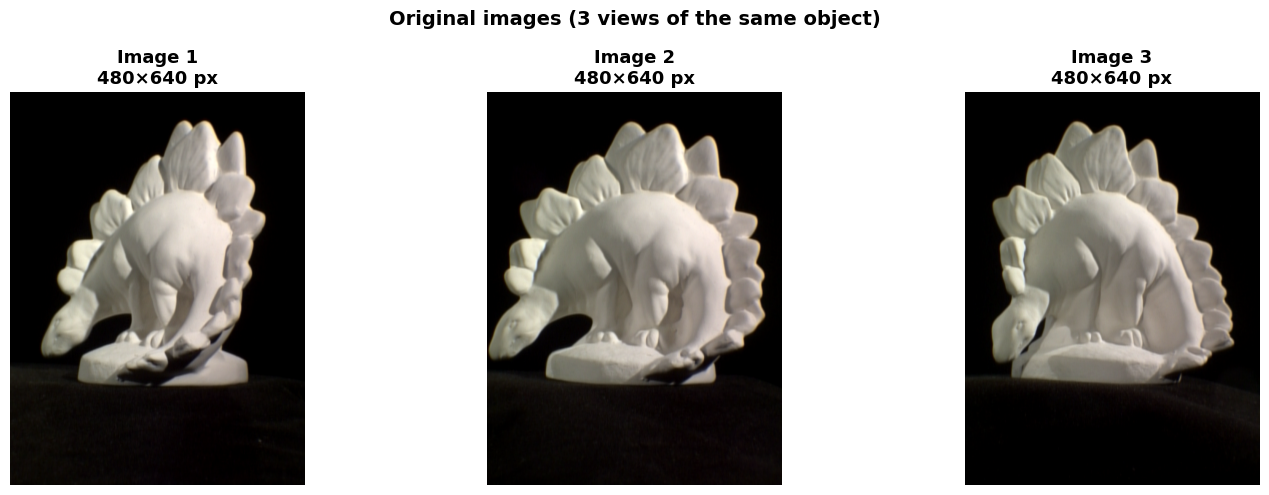

Number of images loaded: 3


In [2]:
import os

# ── Image paths (Kaggle dataset first, local "images/" folder as a fallback)
KAGGLE_DIR = "/kaggle/input/datasets/narimened/dino-images"
IMAGE_DIR = KAGGLE_DIR if os.path.isdir(KAGGLE_DIR) else "images"
image_paths = [os.path.join(IMAGE_DIR, f"im{k}.png") for k in (1, 2, 3)]
image_names = ["Image 1", "Image 2", "Image 3"]

# ── Load as grayscale (and keep an RGB copy for display)
images_gray = []
images_color = []

for path in image_paths:
    img_bgr = cv2.imread(path)
    img_gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    images_color.append(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB))
    images_gray.append(img_gray)

# ── Display
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for i, (img, name) in enumerate(zip(images_color, image_names)):
    axes[i].imshow(img)
    axes[i].set_title(f"{name}\n{img.shape[1]}×{img.shape[0]} px")
    axes[i].axis('off')
plt.suptitle("Original images (3 views of the same object)", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print(f"Number of images loaded: {len(images_gray)}")

## 1.2 Edge extraction with the LoG filter

### What is the LoG filter?

The **LoG (Laplacian of Gaussian)** is a two-step filter:

1. **Gaussian**: smooths the image to reduce noise

2. **Laplacian**: computes the second derivative (detects intensity transitions)

Edges correspond to the **zero crossings** of the LoG.
The `sigma` parameter controls the scale: **large sigma → coarse edges**, **small sigma → fine edges**.

### Why LoG and not Canny?
The assignment explicitly requires LoG. LoG is also more robust across different structure scales.

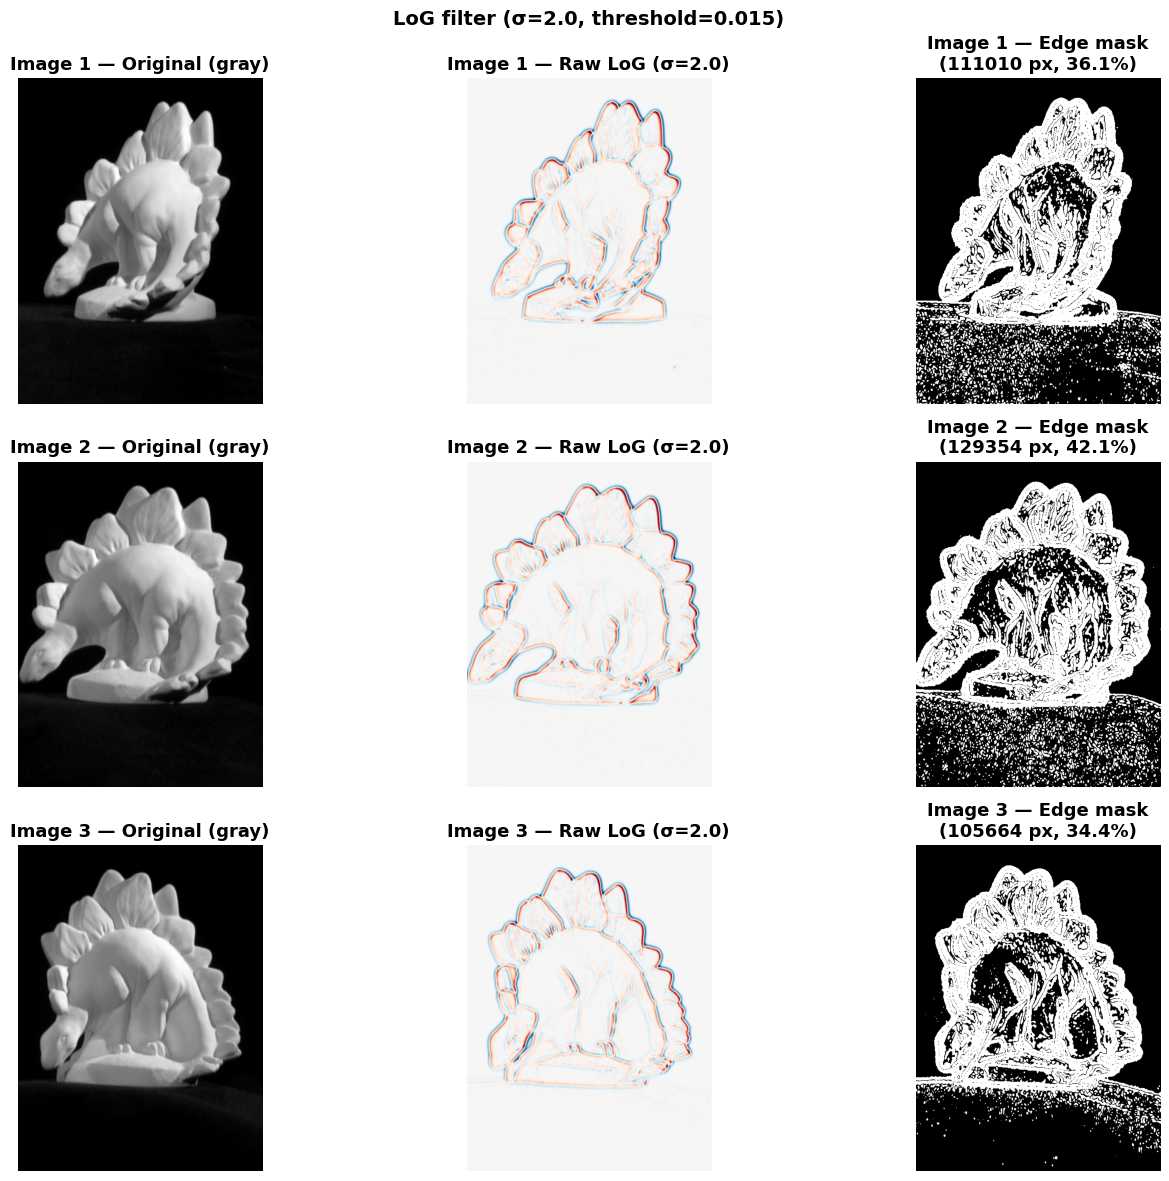

In [3]:
def apply_log_filter(gray_image, sigma=2.0, threshold=0.01):
    """
    Apply the LoG filter and extract edges by thresholding.

    Parameters
    ----------
    gray_image : np.ndarray
        Grayscale image (uint8)
    sigma : float
        Standard deviation of the Gaussian (controls the edge scale)
    threshold : float
        Threshold on the absolute value of the normalized LoG response

    Returns
    -------
    log_raw : np.ndarray (float)
        Raw LoG filter response
    contour_mask : np.ndarray (uint8)
        Binary edge mask (0 or 255)
    """
    # Normalize to [0, 1] for numerical stability
    img_float = gray_image.astype(np.float64) / 255.0

    # Apply the LoG with scipy (accurate implementation)
    log_raw = gaussian_laplace(img_float, sigma=sigma)

    # Normalize the response before thresholding
    log_abs = np.abs(log_raw)
    log_norm = log_abs / (log_abs.max() + 1e-8)

    # Thresholding: pixels > threshold → edge
    contour_mask = (log_norm > threshold).astype(np.uint8) * 255

    return log_raw, contour_mask


# ── Parameters
SIGMA = 2.0
THRESHOLD = 0.015

# ── Apply to the 3 images
log_raws = []
contour_masks = []

for img_gray in images_gray:
    log_raw, mask = apply_log_filter(img_gray, sigma=SIGMA, threshold=THRESHOLD)
    log_raws.append(log_raw)
    contour_masks.append(mask)

# ── Display: original + raw LoG + edge mask
fig, axes = plt.subplots(3, 3, figsize=(15, 12))

for i in range(3):
    # Column 1: original image
    axes[i, 0].imshow(images_gray[i], cmap='gray')
    axes[i, 0].set_title(f"{image_names[i]} — Original (gray)")
    axes[i, 0].axis('off')

    # Column 2: raw LoG response
    axes[i, 1].imshow(log_raws[i], cmap='RdBu', vmin=-0.05, vmax=0.05)
    axes[i, 1].set_title(f"{image_names[i]} — Raw LoG (σ={SIGMA})")
    axes[i, 1].axis('off')

    # Column 3: edge mask
    axes[i, 2].imshow(contour_masks[i], cmap='gray')
    n_pixels = np.sum(contour_masks[i] > 0)
    pct = 100 * n_pixels / contour_masks[i].size
    axes[i, 2].set_title(f"{image_names[i]} — Edge mask\n({n_pixels} px, {pct:.1f}%)")
    axes[i, 2].axis('off')

plt.suptitle(f"LoG filter (σ={SIGMA}, threshold={THRESHOLD})", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## 1.3 Morphological dilation of the mask

### Why dilate?

The LoG mask produces **thin** edges (1-2 pixels).
SIFT needs **regions** around keypoints to compute its descriptors.
**Dilation** widens the edges → more usable area for SIFT.

### How dilation works
A **structuring element** (kernel) is slid over the mask.
A pixel becomes white if **at least one neighbouring pixel** inside the kernel window is white.

**5×5 elliptical kernel**: a good compromise between widening the edges and preserving their shape.

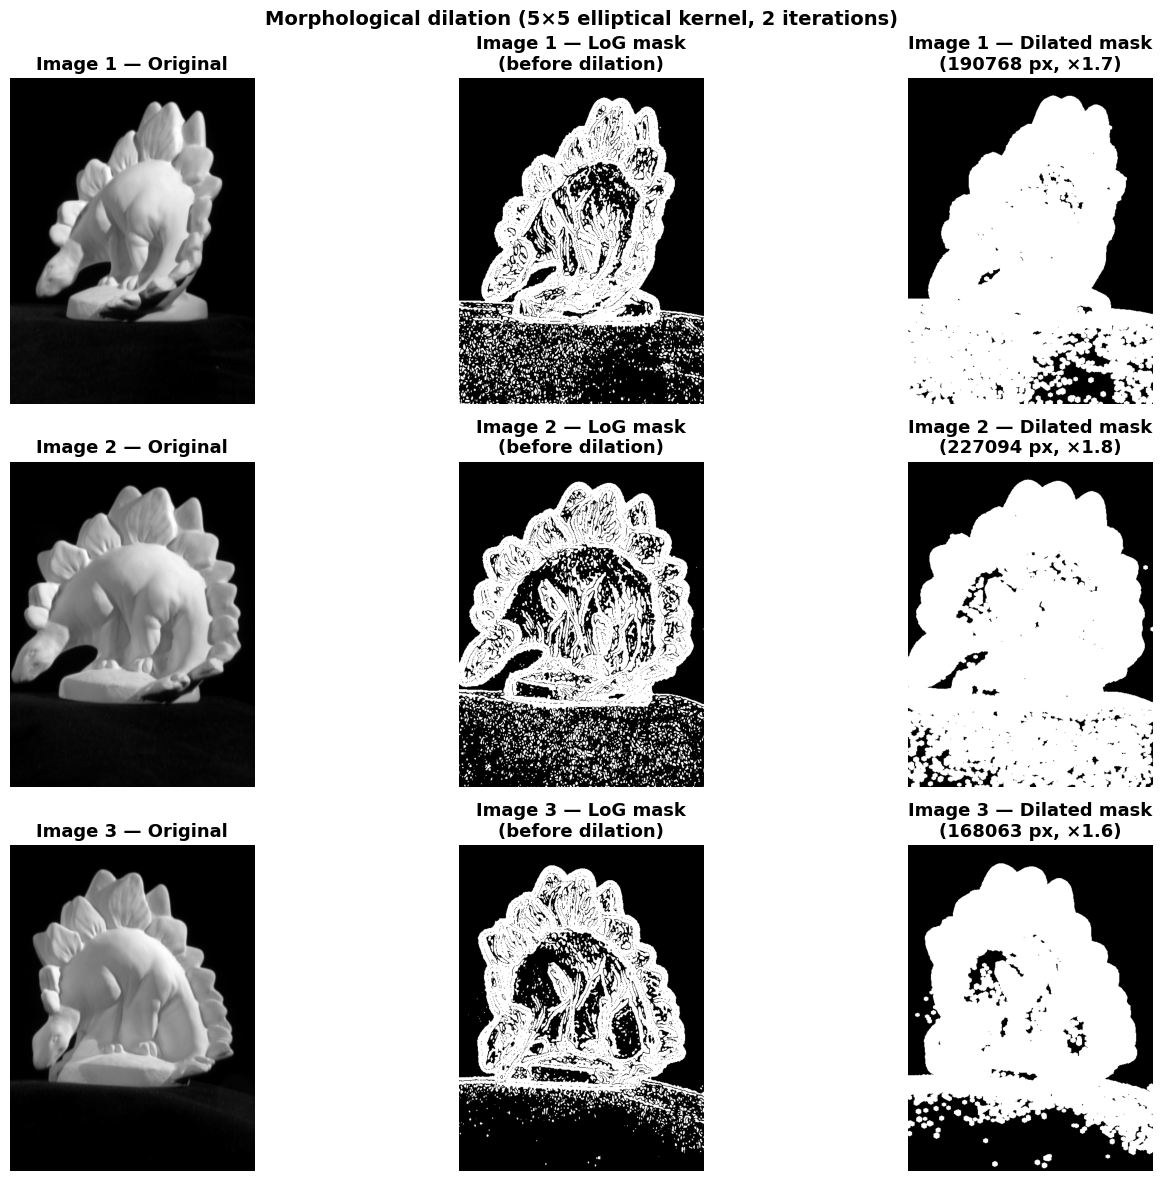

Image       Before (px)   After (px)    Ratio
Image 1         111,010      190,768     1.72×
Image 2         129,354      227,094     1.76×
Image 3         105,664      168,063     1.59×


In [4]:
def apply_dilation(mask, kernel_size=5, iterations=1):
    """
    Apply morphological dilation to a binary mask.

    Parameters
    ----------
    mask : np.ndarray (uint8)
        Binary mask (0 or 255)
    kernel_size : int
        Kernel size (square kernel_size × kernel_size)
    iterations : int
        Number of times the dilation is applied

    Returns
    -------
    dilated : np.ndarray (uint8)
        Dilated mask
    """
    # Elliptical kernel (more natural than a square for edges)
    kernel = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE,
        (kernel_size, kernel_size)
    )
    dilated = cv2.dilate(mask, kernel, iterations=iterations)
    return dilated


# ── Parameters
KERNEL_SIZE = 5
DILATION_ITER = 2

# ── Apply
dilated_masks = []
for mask in contour_masks:
    dilated = apply_dilation(mask, kernel_size=KERNEL_SIZE, iterations=DILATION_ITER)
    dilated_masks.append(dilated)

# ── Display: mask before / after dilation
fig, axes = plt.subplots(3, 3, figsize=(15, 12))

for i in range(3):
    # Original image
    axes[i, 0].imshow(images_gray[i], cmap='gray')
    axes[i, 0].set_title(f"{image_names[i]} — Original")
    axes[i, 0].axis('off')

    # LoG mask (before dilation)
    axes[i, 1].imshow(contour_masks[i], cmap='gray')
    axes[i, 1].set_title(f"{image_names[i]} — LoG mask\n(before dilation)")
    axes[i, 1].axis('off')

    # Dilated mask
    axes[i, 2].imshow(dilated_masks[i], cmap='gray')
    n_before = np.sum(contour_masks[i] > 0)
    n_after  = np.sum(dilated_masks[i] > 0)
    ratio    = n_after / (n_before + 1e-8)
    axes[i, 2].set_title(f"{image_names[i]} — Dilated mask\n({n_after} px, ×{ratio:.1f})")
    axes[i, 2].axis('off')

plt.suptitle(f"Morphological dilation ({KERNEL_SIZE}×{KERNEL_SIZE} elliptical kernel, {DILATION_ITER} iterations)",
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# Summary
print("=" * 55)
print(f"{'Image':<10} {'Before (px)':>12} {'After (px)':>12} {'Ratio':>8}")

for i in range(3):
    n_b = np.sum(contour_masks[i] > 0)
    n_a = np.sum(dilated_masks[i] > 0)
    print(f"{image_names[i]:<10} {n_b:>12,} {n_a:>12,} {n_a/n_b:>8.2f}×")

---
# PART 2 — SIFT detection on the edge mask

## 2.1 The SIFT principle

**SIFT (Scale-Invariant Feature Transform)** — Lowe, 2004 — detects and describes interest points that are **invariant** to:
- **Translation**
- **Rotation**
- **Scale change**
- Partially to **illumination changes**

### Internal SIFT steps

| Step | Description |
|-------|-------------|
| 1. DoG (Difference of Gaussians) | Approximates the LoG at several scales |
| 2. Extrema detection | Finds local maxima/minima in scale space |
| 3. Keypoint selection | Filters out low-contrast points and points lying on edges |
| 4. Orientation | Assigns a dominant direction (rotation invariance) |
| 5. 128-D descriptor | Gradient histograms in a 16×16 window → 128-dimensional vector |

### Role of the mask
By passing `mask=dilated_mask` to SIFT, we **restrict detection to edge regions**.
Expected advantage: less noise, more structurally relevant points.

SIFT with edge mask
Image 1:   187 keypoints detected  |  descriptors: 187 × 128
Image 2:   212 keypoints detected  |  descriptors: 212 × 128
Image 3:   214 keypoints detected  |  descriptors: 214 × 128


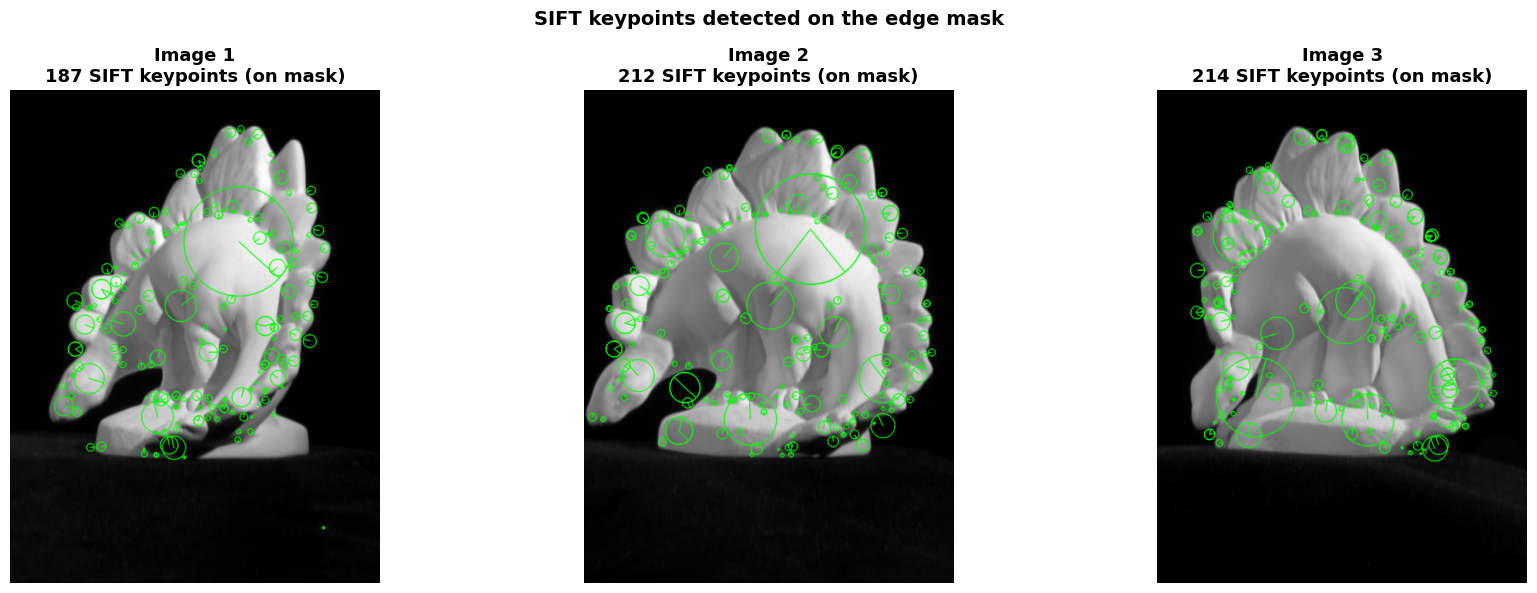

In [5]:
def detect_sift_keypoints(gray_image, mask=None, n_features=0):
    """
    Detect SIFT keypoints and compute their descriptors.

    Parameters
    ----------
    gray_image : np.ndarray (uint8)
        Grayscale image
    mask : np.ndarray (uint8) or None
        Binary mask (255 = allowed area). None = full image.
    n_features : int
        0 = no limit on the number of keypoints

    Returns
    -------
    keypoints : list[cv2.KeyPoint]
    descriptors : np.ndarray (N × 128)
    """
    sift = cv2.SIFT_create(nfeatures=n_features)
    keypoints, descriptors = sift.detectAndCompute(gray_image, mask=mask)
    return keypoints, descriptors


def draw_keypoints_on_image(gray_image, keypoints, color=(0, 255, 0)):
    """Draw the keypoints on a copy of the image (with circles and orientation)."""
    img_color = cv2.cvtColor(gray_image, cv2.COLOR_GRAY2BGR)
    img_kp = cv2.drawKeypoints(
        img_color, keypoints, None,
        flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS,
        color=color
    )
    return cv2.cvtColor(img_kp, cv2.COLOR_BGR2RGB)


# ── SIFT with the edge mask
kp_masked   = []
desc_masked = []

print("SIFT with edge mask")

for i, (img, mask, name) in enumerate(zip(images_gray, dilated_masks, image_names)):
    kp, desc = detect_sift_keypoints(img, mask=mask)
    kp_masked.append(kp)
    desc_masked.append(desc)
    n_desc = desc.shape[0] if desc is not None else 0
    print(f"{name}: {len(kp):>5} keypoints detected  |  descriptors: {n_desc} × 128")


# ── Keypoint visualization
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for i in range(3):
    img_kp = draw_keypoints_on_image(images_gray[i], kp_masked[i])
    axes[i].imshow(img_kp)
    axes[i].set_title(f"{image_names[i]}\n{len(kp_masked[i])} SIFT keypoints (on mask)")
    axes[i].axis('off')

plt.suptitle("SIFT keypoints detected on the edge mask", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

---
# PART 3 — FLANN matching

## 3.1 The FLANN principle

**FLANN (Fast Library for Approximate Nearest Neighbors)** efficiently searches, for each descriptor of one image, its **k nearest neighbours** in the descriptor space of the other image.

### Filtering with Lowe's ratio test
For each point, FLANN finds the **2 best neighbours** (k=2).
A match is accepted only if:

$$\frac{d_1}{d_2} < 0.75$$

Where $d_1$ = distance to the 1st neighbour, $d_2$ = distance to the 2nd neighbour.
If the ratio is small → the 1st neighbour is clearly better → reliable match.
If the ratio is close to 1 → ambiguity → the match is rejected.

In [6]:
def flann_matching(desc1, desc2, ratio_threshold=0.75):
    """
    Match two sets of SIFT descriptors using FLANN + Lowe's ratio test.

    Parameters
    ----------
    desc1, desc2 : np.ndarray (N × 128)
        Descriptors of the two images
    ratio_threshold : float
        Ratio test threshold (Lowe recommends 0.75)

    Returns
    -------
    good_matches : list[cv2.DMatch]
        Matches that pass the filtering
    """
    if desc1 is None or desc2 is None:
        return []

    # FLANN configuration for SIFT descriptors (float32)
    FLANN_INDEX_KDTREE = 1
    index_params  = dict(algorithm=FLANN_INDEX_KDTREE, trees=5)
    search_params = dict(checks=50)  # more checks = more accurate but slower

    flann = cv2.FlannBasedMatcher(index_params, search_params)

    # float32 conversion is required by FLANN
    d1 = desc1.astype(np.float32)
    d2 = desc2.astype(np.float32)

    # k=2: the 2 nearest neighbours
    matches = flann.knnMatch(d1, d2, k=2)

    # Lowe's ratio test
    good_matches = []
    for match_pair in matches:
        if len(match_pair) == 2:
            m, n = match_pair
            if m.distance < ratio_threshold * n.distance:
                good_matches.append(m)

    return good_matches


def visualize_matches(img1, kp1, img2, kp2, matches, title="", max_display=60):
    """
    Visualize the matches between two images.
    Display is limited to max_display matches for readability.
    """
    # Keep the best matches (sorted by distance)
    sorted_matches = sorted(matches, key=lambda x: x.distance)
    display_matches = sorted_matches[:max_display]

    img_matches = cv2.drawMatches(
        img1, kp1, img2, kp2,
        display_matches, None,
        matchColor=(0, 255, 0),
        singlePointColor=(255, 0, 0),
        flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
    )
    return cv2.cvtColor(img_matches, cv2.COLOR_BGR2RGB)


print("FLANN functions defined ✓")

FLANN functions defined ✓


## 3.2 FLANN matching with the edge mask

We apply FLANN to the **3 possible pairs**:
- Image 1 ↔ Image 2
- Image 1 ↔ Image 3
- Image 2 ↔ Image 3

FLANN matching with edge mask
Im1 ↔ Im2:   40 valid matches (kp: 187 vs 212, rate: 21.4%)
Im1 ↔ Im3:    6 valid matches (kp: 187 vs 214, rate: 3.2%)
Im2 ↔ Im3:   42 valid matches (kp: 212 vs 214, rate: 19.8%)


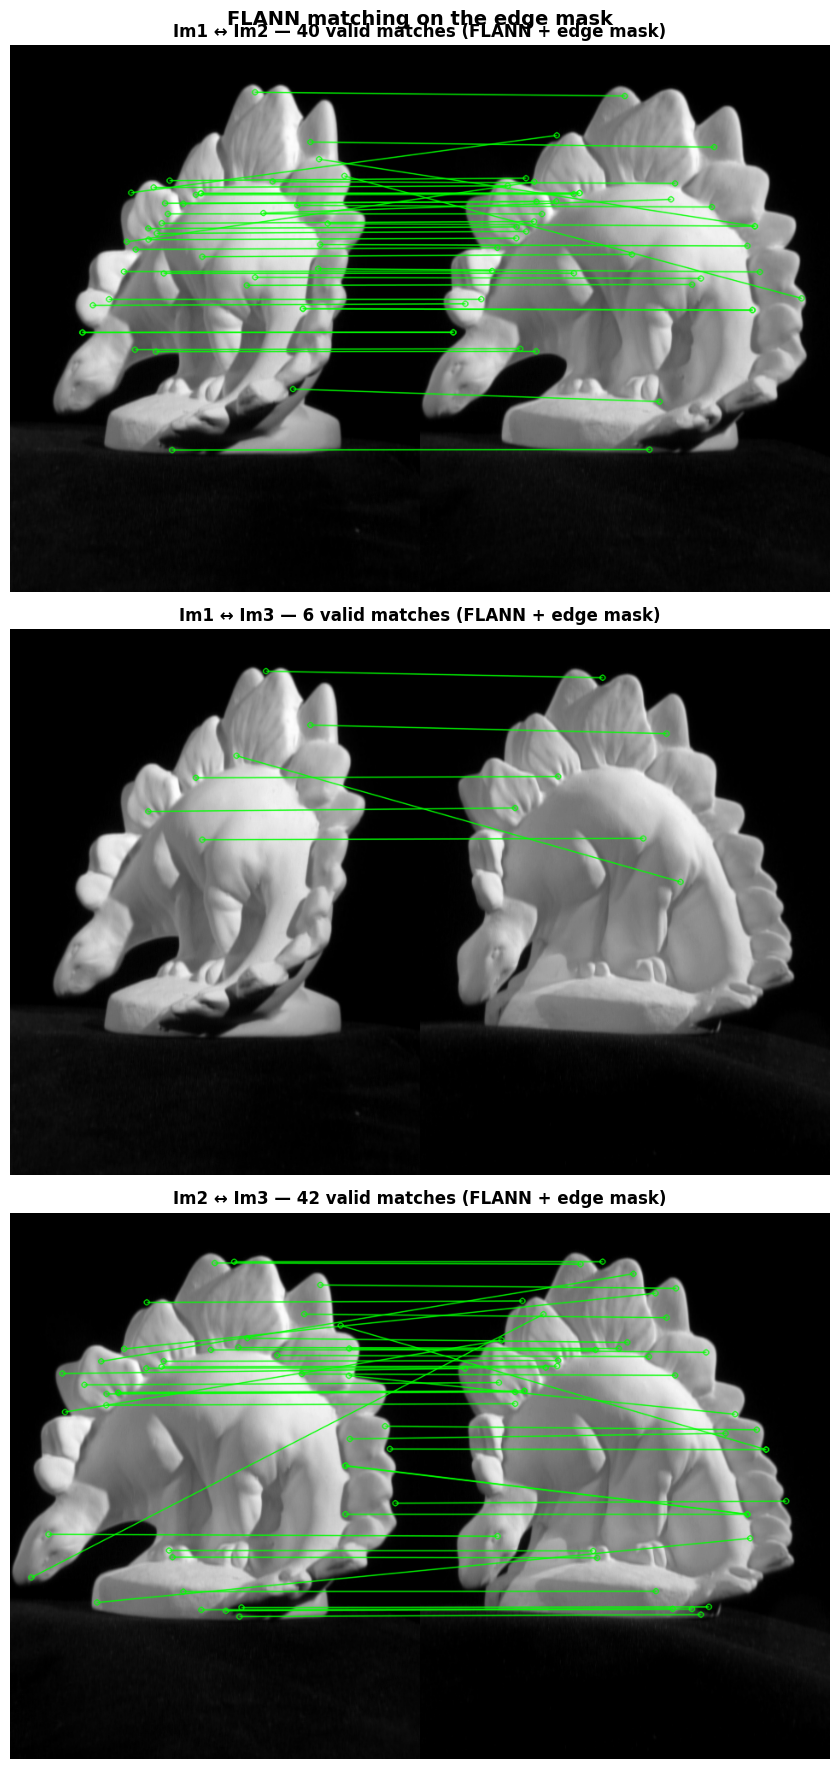

In [7]:
# ── Define the 3 pairs
pairs = [(0, 1), (0, 2), (1, 2)]
pair_names = ["Im1 ↔ Im2", "Im1 ↔ Im3", "Im2 ↔ Im3"]

# ── FLANN matching on the mask
matches_masked = {}
print("FLANN matching with edge mask")


for (i, j), pname in zip(pairs, pair_names):
    matches = flann_matching(desc_masked[i], desc_masked[j])
    matches_masked[(i, j)] = matches

    n_kp_i = len(kp_masked[i])
    n_kp_j = len(kp_masked[j])
    pct = 100 * len(matches) / min(n_kp_i, n_kp_j) if min(n_kp_i, n_kp_j) > 0 else 0

    print(f"{pname}: {len(matches):>4} valid matches "
          f"(kp: {n_kp_i} vs {n_kp_j}, rate: {pct:.1f}%)")



# ── Visualization
fig, axes = plt.subplots(3, 1, figsize=(18, 18))

for idx, ((i, j), pname) in enumerate(zip(pairs, pair_names)):
    img_match = visualize_matches(
        images_gray[i], kp_masked[i],
        images_gray[j], kp_masked[j],
        matches_masked[(i, j)]
    )
    axes[idx].imshow(img_match)
    axes[idx].set_title(
        f"{pname} — {len(matches_masked[(i,j)])} valid matches (FLANN + edge mask)",
        fontsize=12
    )
    axes[idx].axis('off')

plt.suptitle("FLANN matching on the edge mask", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## 3.3 SIFT on the full image (no mask) + FLANN

We repeat exactly the same procedure but **without a mask** — SIFT runs on the whole image.

SIFT without mask (full image)
Image 1:   194 keypoints  |  descriptors: 194 × 128
Image 2:   212 keypoints  |  descriptors: 212 × 128
Image 3:   218 keypoints  |  descriptors: 218 × 128

FLANN matching without mask
Im1 ↔ Im2:   39 valid matches (kp: 194 vs 212, rate: 20.1%)
Im1 ↔ Im3:    6 valid matches (kp: 194 vs 218, rate: 3.1%)
Im2 ↔ Im3:   43 valid matches (kp: 212 vs 218, rate: 20.3%)


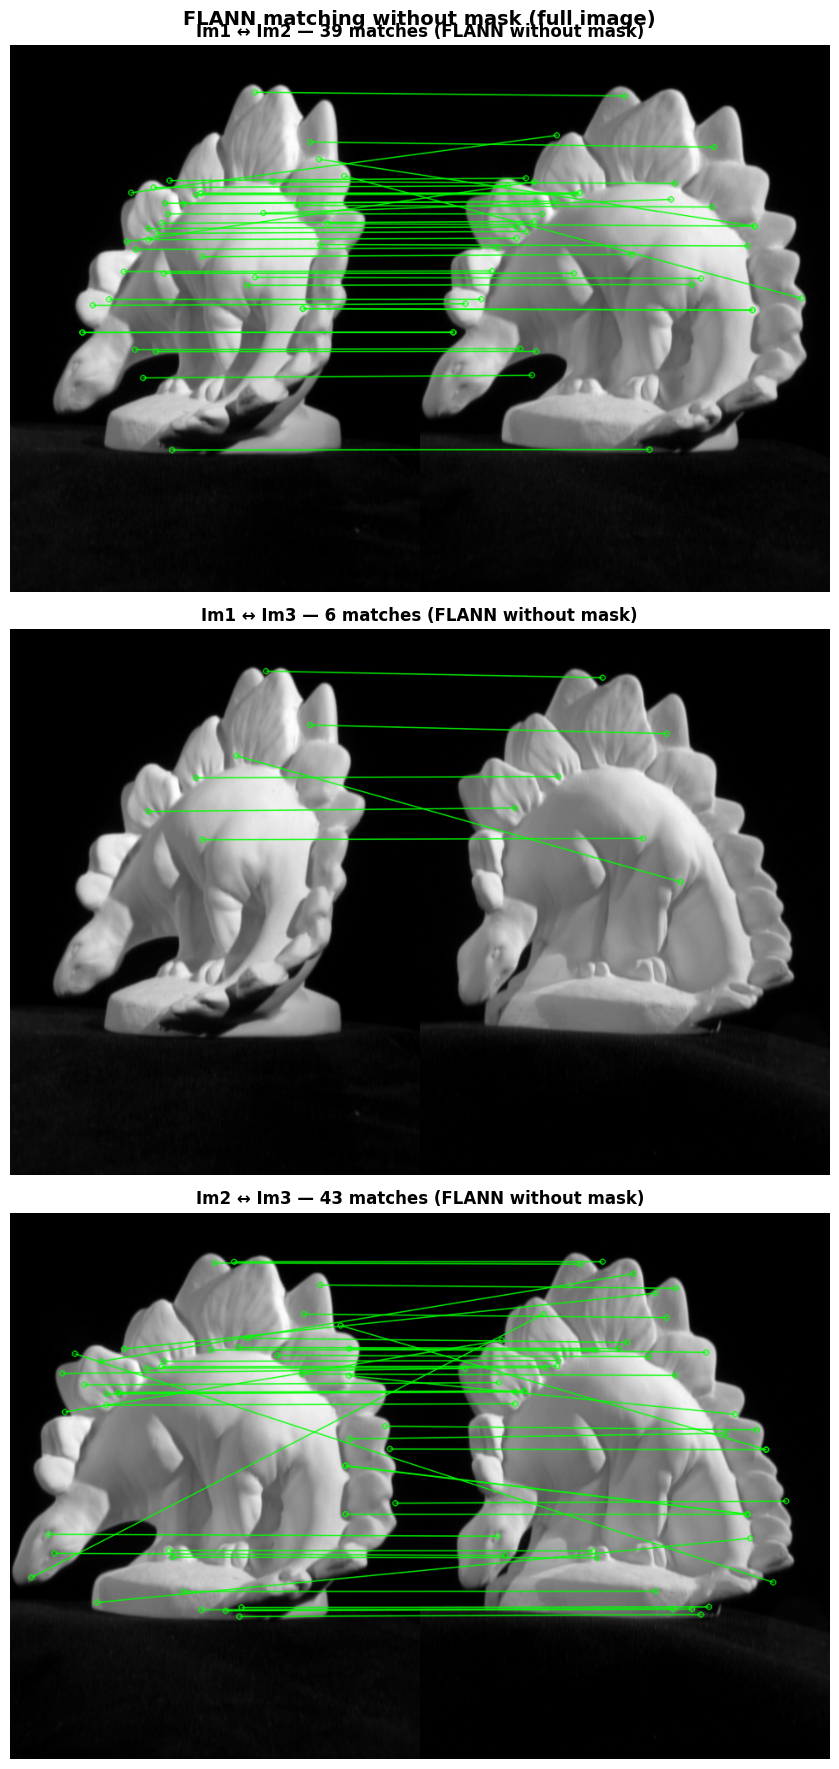

In [8]:
# ── SIFT without mask (full image)
kp_full   = []
desc_full = []

print("SIFT without mask (full image)")

for i, (img, name) in enumerate(zip(images_gray, image_names)):
    kp, desc = detect_sift_keypoints(img, mask=None)  # <-- no mask
    kp_full.append(kp)
    desc_full.append(desc)
    print(f"{name}: {len(kp):>5} keypoints  |  descriptors: {desc.shape[0]} × 128")


# ── FLANN matching without mask
matches_full = {}
print("\nFLANN matching without mask")


for (i, j), pname in zip(pairs, pair_names):
    matches = flann_matching(desc_full[i], desc_full[j])
    matches_full[(i, j)] = matches

    n_kp_i = len(kp_full[i])
    n_kp_j = len(kp_full[j])
    pct = 100 * len(matches) / min(n_kp_i, n_kp_j) if min(n_kp_i, n_kp_j) > 0 else 0

    print(f"{pname}: {len(matches):>4} valid matches "
          f"(kp: {n_kp_i} vs {n_kp_j}, rate: {pct:.1f}%)")



# ── Visualization
fig, axes = plt.subplots(3, 1, figsize=(18, 18))

for idx, ((i, j), pname) in enumerate(zip(pairs, pair_names)):
    img_match = visualize_matches(
        images_gray[i], kp_full[i],
        images_gray[j], kp_full[j],
        matches_full[(i, j)]
    )
    axes[idx].imshow(img_match)
    axes[idx].set_title(
        f"{pname} — {len(matches_full[(i,j)])} matches (FLANN without mask)",
        fontsize=12
    )
    axes[idx].axis('off')

plt.suptitle("FLANN matching without mask (full image)", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## 3.4 Comparison and analysis of the results

                               RESULTS COMPARISON                               
Pair           KP masked     KP full   Matches masked     Matches full   Δ matches
Im1 ↔ Im2            187         194               40               39          -1
Im1 ↔ Im3            187         194                6                6          +0
Im2 ↔ Im3            212         212               42               43          +1
TOTAL                                              88               88          +0


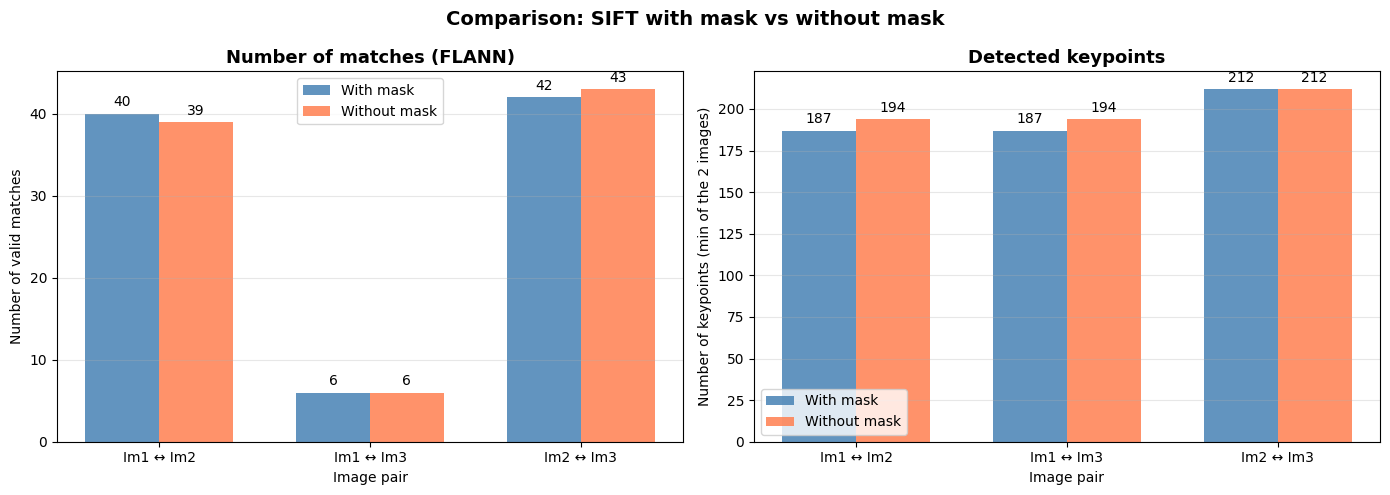

In [9]:
# ── Comparison table
print(f"{'RESULTS COMPARISON':^80}")

print(f"{'Pair':<12} {'KP masked':>11} {'KP full':>11} {'Matches masked':>16} {'Matches full':>16} {'Δ matches':>11}")


total_masked = 0
total_full   = 0

for (i, j), pname in zip(pairs, pair_names):
    kp_m  = min(len(kp_masked[i]), len(kp_masked[j]))
    kp_f  = min(len(kp_full[i]),   len(kp_full[j]))
    n_m   = len(matches_masked[(i, j)])
    n_f   = len(matches_full[(i, j)])
    delta = n_f - n_m
    total_masked += n_m
    total_full   += n_f
    print(f"{pname:<12} {kp_m:>11} {kp_f:>11} {n_m:>16} {n_f:>16} {delta:>+11}")


print(f"{'TOTAL':<12} {'':>11} {'':>11} {total_masked:>16} {total_full:>16} {total_full-total_masked:>+11}")


# ── Comparison charts
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

x = np.arange(len(pair_names))
width = 0.35

n_masked_vals = [len(matches_masked[(i,j)]) for (i,j) in pairs]
n_full_vals   = [len(matches_full[(i,j)])   for (i,j) in pairs]

# Chart 1: number of matches
bars1 = axes[0].bar(x - width/2, n_masked_vals, width, label='With mask',    color='steelblue', alpha=0.85)
bars2 = axes[0].bar(x + width/2, n_full_vals,   width, label='Without mask', color='coral',     alpha=0.85)
axes[0].set_xlabel('Image pair')
axes[0].set_ylabel('Number of valid matches')
axes[0].set_title('Number of matches (FLANN)')
axes[0].set_xticks(x)
axes[0].set_xticklabels(pair_names)
axes[0].legend()
axes[0].bar_label(bars1, padding=3)
axes[0].bar_label(bars2, padding=3)
axes[0].grid(axis='y', alpha=0.3)

# Chart 2: number of keypoints
kp_masked_min = [min(len(kp_masked[i]), len(kp_masked[j])) for (i,j) in pairs]
kp_full_min   = [min(len(kp_full[i]),   len(kp_full[j]))   for (i,j) in pairs]

bars3 = axes[1].bar(x - width/2, kp_masked_min, width, label='With mask',    color='steelblue', alpha=0.85)
bars4 = axes[1].bar(x + width/2, kp_full_min,   width, label='Without mask', color='coral',     alpha=0.85)
axes[1].set_xlabel('Image pair')
axes[1].set_ylabel('Number of keypoints (min of the 2 images)')
axes[1].set_title('Detected keypoints')
axes[1].set_xticks(x)
axes[1].set_xticklabels(pair_names)
axes[1].legend()
axes[1].bar_label(bars3, padding=3)
axes[1].bar_label(bars4, padding=3)
axes[1].grid(axis='y', alpha=0.3)

plt.suptitle("Comparison: SIFT with mask vs without mask", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## 3.5 Conclusion and analysis

### Summary of results (from our run)

| Approach | Keypoints (Image 1 / 2 / 3) | Total valid matches (3 pairs) | Detection area |
|----------|------------|-----------------|-----------|
| **SIFT + LoG mask** | 187 / 212 / 214 | 88 | Edge regions only |
| **SIFT on full image** | 194 / 212 / 218 | 88 | Whole image |

### Analysis

**The two approaches give almost identical results on these images:**
- The number of keypoints differs by at most 7 per image, and the total number of valid matches is the same (88) in both cases; per-pair differences are at most ±1 match.
- A likely reason: the background is dark and almost featureless. SIFT's own filtering (low-contrast rejection) already discards such regions, so nearly all keypoints fall on the object's structure whether or not a mask is used.
- The mask only restricts **where keypoints are detected**; the descriptors are still computed from the original image gradients, so the matched points are essentially the same.

**Effect of the viewpoint:**
- Im1 ↔ Im3 yields far fewer matches (6) than the other two pairs (about 40 each), which suggests a larger viewpoint change between these two views.

**Conclusion:** On this dataset (a single object on a clean background), restricting SIFT to LoG edges brings no measurable gain over running SIFT on the full image. The mask is expected to matter more with a cluttered background, where it would remove keypoints on irrelevant structures. In both cases, the raw matches may still contain outliers, so a geometric verification step (e.g. RANSAC) would be needed to keep only the consistent correspondences.